In [1]:
# Check GPU availability

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU device:", torch.cuda.get_device_name(0))
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Using device:", DEVICE)

PyTorch version: 2.14.1+cu130
GPU available: True
GPU device: Tesla T4
Using device: cuda


In [2]:
# Mount Google Drive and inspect My Drive

from google.colab import drive
drive.mount('/content/drive')

import os

MYDRIVE = "/content/drive/MyDrive"

print("My Drive contents:")
for item in os.listdir(MYDRIVE):
    print(item)

Mounted at /content/drive
My Drive contents:
test
best_unet.pth
Colab Notebooks


In [3]:
# Copy processed test dataset from Drive to Colab

import shutil

SOURCE = "/content/drive/MyDrive/test"
DESTINATION = "/content/test"

shutil.copytree(SOURCE, DESTINATION, dirs_exist_ok=True)

print("Test dataset copied successfully!")
print("Destination:", DESTINATION)
print("Contents:", os.listdir(DESTINATION))

Test dataset copied successfully!
Destination: /content/test
Contents: ['images', 'masks']


In [6]:
# Load test dataset

class BrainTumorSegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)

        self.images = sorted(self.image_dir.glob("*"))
        self.masks = sorted(self.mask_dir.glob("*"))

        mask_map = {mask.stem: mask for mask in self.masks}
        self.pairs = [(img, mask_map[img.stem]) for img in self.images if img.stem in mask_map]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]

        image = np.array(Image.open(image_path).convert("L"), dtype=np.float32) / 255.0
        mask = np.array(Image.open(mask_path).convert("L"), dtype=np.float32) / 255.0
        mask = (mask >= 0.5).astype(np.float32)

        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


test_dataset = BrainTumorSegmentationDataset(
    "/content/test/images",
    "/content/test/masks"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))

Test images: 860
Test batches: 108


In [5]:
# Import required libraries

import numpy as np
from pathlib import Path
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

In [10]:
# Recreate the trained U-Net architecture

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base_channels=64):
        super().__init__()

        self.encoder1 = DoubleConv(in_channels, base_channels)
        self.encoder2 = DoubleConv(base_channels, base_channels * 2)
        self.encoder3 = DoubleConv(base_channels * 2, base_channels * 4)
        self.encoder4 = DoubleConv(base_channels * 4, base_channels * 8)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base_channels * 8, base_channels * 16)

        self.upconv4 = nn.ConvTranspose2d(base_channels * 16, base_channels * 8, 2, stride=2)
        self.decoder4 = DoubleConv(base_channels * 16, base_channels * 8)

        self.upconv3 = nn.ConvTranspose2d(base_channels * 8, base_channels * 4, 2, stride=2)
        self.decoder3 = DoubleConv(base_channels * 8, base_channels * 4)

        self.upconv2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, 2, stride=2)
        self.decoder2 = DoubleConv(base_channels * 4, base_channels * 2)

        self.upconv1 = nn.ConvTranspose2d(base_channels * 2, base_channels, 2, stride=2)
        self.decoder1 = DoubleConv(base_channels * 2, base_channels)

        self.output = nn.Conv2d(base_channels, out_channels, 1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.upconv4(b)
        d4 = self.decoder4(torch.cat([d4, e4], dim=1))

        d3 = self.upconv3(d4)
        d3 = self.decoder3(torch.cat([d3, e3], dim=1))

        d2 = self.upconv2(d3)
        d2 = self.decoder2(torch.cat([d2, e2], dim=1))

        d1 = self.upconv1(d2)
        d1 = self.decoder1(torch.cat([d1, e1], dim=1))

        return self.output(d1)

In [9]:
# Import all required libraries

import torch
import torch.nn as nn
import numpy as np

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [12]:
# Inspect checkpoint structure and model layer names
print("Checkpoint keys:", checkpoint.keys())

state_dict = checkpoint["model_state_dict"]

print("\nFirst 40 model parameter names:")
for key in list(state_dict.keys())[:40]:
    print(key)

Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_dice', 'val_metrics', 'history'])

First 40 model parameter names:
encoder1.block.0.weight
encoder1.block.1.weight
encoder1.block.1.bias
encoder1.block.1.running_mean
encoder1.block.1.running_var
encoder1.block.1.num_batches_tracked
encoder1.block.3.weight
encoder1.block.4.weight
encoder1.block.4.bias
encoder1.block.4.running_mean
encoder1.block.4.running_var
encoder1.block.4.num_batches_tracked
encoder2.block.0.weight
encoder2.block.1.weight
encoder2.block.1.bias
encoder2.block.1.running_mean
encoder2.block.1.running_var
encoder2.block.1.num_batches_tracked
encoder2.block.3.weight
encoder2.block.4.weight
encoder2.block.4.bias
encoder2.block.4.running_mean
encoder2.block.4.running_var
encoder2.block.4.num_batches_tracked
encoder3.block.0.weight
encoder3.block.1.weight
encoder3.block.1.bias
encoder3.block.1.running_mean
encoder3.block.1.running_var
encoder3.block.1.num_batches_tracked
encoder3.block.3.

In [13]:
# Inspect remaining checkpoint layer names
for key in list(state_dict.keys())[40:]:
    print(key)

encoder4.block.1.running_var
encoder4.block.1.num_batches_tracked
encoder4.block.3.weight
encoder4.block.4.weight
encoder4.block.4.bias
encoder4.block.4.running_mean
encoder4.block.4.running_var
encoder4.block.4.num_batches_tracked
bottleneck.block.0.weight
bottleneck.block.1.weight
bottleneck.block.1.bias
bottleneck.block.1.running_mean
bottleneck.block.1.running_var
bottleneck.block.1.num_batches_tracked
bottleneck.block.3.weight
bottleneck.block.4.weight
bottleneck.block.4.bias
bottleneck.block.4.running_mean
bottleneck.block.4.running_var
bottleneck.block.4.num_batches_tracked
up4.weight
up4.bias
decoder4.block.0.weight
decoder4.block.1.weight
decoder4.block.1.bias
decoder4.block.1.running_mean
decoder4.block.1.running_var
decoder4.block.1.num_batches_tracked
decoder4.block.3.weight
decoder4.block.4.weight
decoder4.block.4.bias
decoder4.block.4.running_mean
decoder4.block.4.running_var
decoder4.block.4.num_batches_tracked
up3.weight
up3.bias
decoder3.block.0.weight
decoder3.block.1

In [14]:
# Recreate the trained U-Net architecture
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base_channels=64):
        super().__init__()

        self.encoder1 = DoubleConv(in_channels, base_channels)
        self.encoder2 = DoubleConv(base_channels, base_channels * 2)
        self.encoder3 = DoubleConv(base_channels * 2, base_channels * 4)
        self.encoder4 = DoubleConv(base_channels * 4, base_channels * 8)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base_channels * 8, base_channels * 16)

        self.up4 = nn.ConvTranspose2d(base_channels * 16, base_channels * 8, 2, stride=2)
        self.decoder4 = DoubleConv(base_channels * 16, base_channels * 8)

        self.up3 = nn.ConvTranspose2d(base_channels * 8, base_channels * 4, 2, stride=2)
        self.decoder3 = DoubleConv(base_channels * 8, base_channels * 4)

        self.up2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, 2, stride=2)
        self.decoder2 = DoubleConv(base_channels * 4, base_channels * 2)

        self.up1 = nn.ConvTranspose2d(base_channels * 2, base_channels, 2, stride=2)
        self.decoder1 = DoubleConv(base_channels * 2, base_channels)

        self.output = nn.Conv2d(base_channels, out_channels, 1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.decoder4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.decoder3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.decoder2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.decoder1(torch.cat([d1, e1], dim=1))

        return self.output(d1)

In [15]:
# Load trained checkpoint
model = UNet().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint loaded successfully!")
print("Model device:", next(model.parameters()).device)

Checkpoint loaded successfully!
Model device: cuda:0


In [16]:
# Evaluate the trained model on the test dataset
model.eval()

test_loss = 0
dice_scores = []
iou_scores = []
total_tp = 0
total_fp = 0
total_fn = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()

        bce = nn.functional.binary_cross_entropy_with_logits(logits, masks)

        intersection = (probabilities * masks).sum(dim=(1, 2, 3))
        dice_loss = 1 - (2 * intersection + 1e-7) / (
            probabilities.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3)) + 1e-7
        )

        loss = 0.5 * bce + 0.5 * dice_loss.mean()
        test_loss += loss.item()

        for pred, mask in zip(predictions, masks):
            tp = (pred * mask).sum().item()
            fp = (pred * (1 - mask)).sum().item()
            fn = ((1 - pred) * mask).sum().item()

            dice = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)
            iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)

            dice_scores.append(dice)
            iou_scores.append(iou)

            total_tp += tp
            total_fp += fp
            total_fn += fn

test_loss /= len(test_loader)
test_dice = np.mean(dice_scores)
test_iou = np.mean(iou_scores)
test_precision = total_tp / (total_tp + total_fp + 1e-7)
test_recall = total_tp / (total_tp + total_fn + 1e-7)

print("TEST RESULTS")
print("-" * 35)
print(f"Test Loss:    {test_loss:.4f}")
print(f"Dice Score:   {test_dice:.4f}")
print(f"IoU:          {test_iou:.4f}")
print(f"Precision:    {test_precision:.4f}")
print(f"Recall:       {test_recall:.4f}")

TEST RESULTS
-----------------------------------
Test Loss:    0.0889
Dice Score:   0.8478
IoU:          0.7762
Precision:    0.8925
Recall:       0.8666


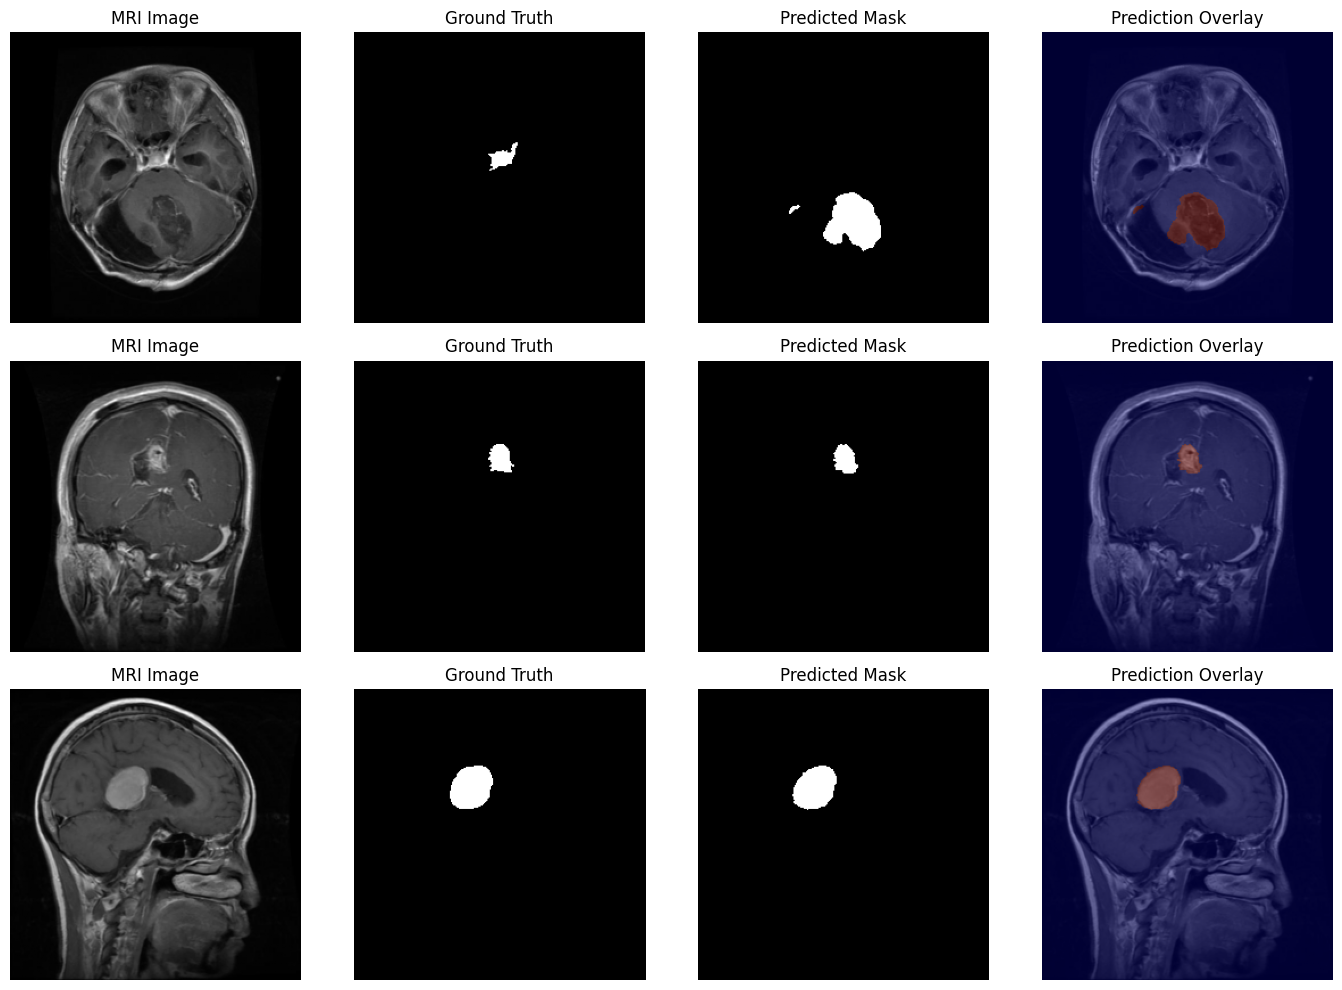

In [17]:
# Visualize segmentation predictions
import matplotlib.pyplot as plt

model.eval()
samples = [0, 100, 500]

fig, axes = plt.subplots(len(samples), 4, figsize=(14, 10))

for row, idx in enumerate(samples):
    image, mask = test_dataset[idx]

    with torch.no_grad():
        image_gpu = image.unsqueeze(0).to(DEVICE)
        prediction = torch.sigmoid(model(image_gpu))
        prediction = (prediction >= 0.5).float().cpu().squeeze().numpy()

    image_np = image.squeeze().numpy()
    mask_np = mask.squeeze().numpy()

    axes[row, 0].imshow(image_np, cmap="gray")
    axes[row, 0].set_title("MRI Image")

    axes[row, 1].imshow(mask_np, cmap="gray")
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(prediction, cmap="gray")
    axes[row, 2].set_title("Predicted Mask")

    axes[row, 3].imshow(image_np, cmap="gray")
    axes[row, 3].imshow(prediction, cmap="jet", alpha=0.4)
    axes[row, 3].set_title("Prediction Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
# Save final segmentation evaluation results
import json
import os

results = {
    "test_loss": float(test_loss),
    "dice_score": float(test_dice),
    "iou": float(test_iou),
    "precision": float(test_precision),
    "recall": float(test_recall),
    "test_images": len(test_dataset)
}

RESULTS_PATH = "/content/drive/MyDrive/segmentation_test_results.json"

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=4)

print("Results saved successfully!")
print(RESULTS_PATH)

Results saved successfully!
/content/drive/MyDrive/segmentation_test_results.json
